# MMP/PICS: defined synthetic cut sites and their proteomic motif frequencies

Represent the six QF substrates with their original Mca/Dpa chemistry and annotated cut. Compare their source-defined four-residue motifs with occurrences in the two PICS peptide libraries, retaining the measured relative activity separately.

## Introduction

**Sources:** primary-paper Figure 6 and its adjoining text (`Activesite.pdf`, DOI 10.1016/j.matbio.2015.09.003), QF measurements in `mmc8.xlsx`, trypsin/GluC windows in `mmc5.xlsx`/`mmc6.xlsx`.

**Assumptions and notation.** Every QF substrate has three ordinary residues before the cut and four residues after it: the latter include the modified amino-acid residue Dpa in P2′. Mca is an N-terminal label and NH₂ is a terminal amide; neither creates an extra positional amino acid. P4 is unavailable, so none of these synthetic substrates supplies a full 4+4 amino-acid window. Dpa remains a distinct residue, never replaced by a standard amino acid. The docking-model sequences APLG↓LLA and APAN↓LLA are not substituted for the measured QF substrates.

A source label such as PLG↓L specifies P3–P1/P1′. Match that four-residue motif to PICS `raw_window[3:7]`. This is a motif-level association: a natural PICS context does not have the same complete chemistry as a Dpa-labelled QF substrate, and it does not inherit that substrate's kinetic measurement. Libraries remain separate. The denominator is the number of source windows with all four motif positions resolved in the selected representation.

All results stay in memory. No integrated dataset or export is written.

In [1]:
from pathlib import Path
import sys
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "assets/tools/proteolysis_data_manager").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
RAW = ROOT / "data/proteolysis/window_neighbourhood_datasets/raw"
from proteolysis_data_manager.analysis.window_neighbourhood.pics import read_qf_assay, MMP_TO_MEROPS, SUBSTRATE_LABELS
logging.getLogger("proteolysis_data_manager.analysis.window_neighbourhood.pics").setLevel(logging.WARNING)
qf = read_qf_assay(RAW / "mmp_pics/mmc8.xlsx")
pd.set_option("display.max_columns", None)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
substrates = qf["substrates"]
display(substrates[["substrate", "full_source_chemistry", "P4", "P3", "P2", "P1", "P1p", "P2p", "P3p", "P4p"]].fillna("unavailable"))
assert substrates["P4"].isna().all()
assert substrates["P2p"].eq("Dpa").all()

,substrate,full_source_chemistry,P4,P3,P2,P1,P1p,P2p,P3p,P4p
0,PLG↓L,Mca-PLG↓L-Dpa-AR-NH2,unavailable,P,L,G,L,Dpa,A,R
1,PAN↓L,Mca-PAN↓L-Dpa-AR-NH2,unavailable,P,A,N,L,Dpa,A,R
2,PLN↓L,Mca-PLN↓L-Dpa-AR-NH2,unavailable,P,L,N,L,Dpa,A,R
3,PAG↓L,Mca-PAG↓L-Dpa-AR-NH2,unavailable,P,A,G,L,Dpa,A,R
4,VLG↓L,Mca-VLG↓L-Dpa-AR-NH2,unavailable,V,L,G,L,Dpa,A,R
5,VAN↓L,Mca-VAN↓L-Dpa-AR-NH2,unavailable,V,A,N,L,Dpa,A,R


## Count the defined motifs in each proteomic library

Select an original window representation explicitly. `PICS Output - unique` uses the deposited unique-window column; it does not combine it with `PICS Output`. Read the named window column, check it against the authors' source counter, then count each motif within the enzyme/library stratum. Missing motif positions are excluded from the denominator, not turned into negative cleavage evidence.

In [3]:
import re
REPRESENTATION = "PICS Output - unique"

source_records = []
for filename, suffix, library in (("mmc5.xlsx", "_T", "trypsin"), ("mmc6.xlsx", "_G", "GluC")):
    with pd.ExcelFile(RAW / "mmp_pics" / filename) as workbook:
        for sheet in workbook.sheet_names:
            if not sheet.endswith(suffix):
                continue
            frame = pd.read_excel(workbook, sheet_name=sheet, header=None)
            headers = np.argwhere(frame.eq(REPRESENTATION).to_numpy())  # (H, 2)
            candidates = []
            for row, column in headers:
                values = frame.iloc[row + 1:, column].dropna()
                if values.astype(str).str.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY-]{12}").any():
                    candidates.append((row, column, values))
            if len(candidates) != 1:
                raise ValueError(f"Ambiguous source window column: {filename}/{sheet}")
            _, column, values = candidates[0]
            counters = [frame.iat[int(row + 1), int(col)] for row, col in headers
                        if isinstance(frame.iat[int(row + 1), int(col)], (int, float, np.number))]
            if len(counters) != 1 or counters[0] != len(values):
                raise ValueError(f"Source window count mismatch: {filename}/{sheet}")
            for row, window in values.items():
                if not isinstance(window, str) or not re.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY-]{12}", window):
                    raise ValueError(f"Unsupported source window: {filename}/{sheet}/{row + 1}")
                source_records.append({"enzyme": sheet[:-len(suffix)], "library": library,
                                       "source_file": filename, "sheet": sheet, "excel_row": row + 1,
                                       "raw_window": window, "motif": window[3:7]})
pics_windows = pd.DataFrame(source_records)
rows = []
for (enzyme, library), group in pics_windows.groupby(["enzyme", "library"]):
    eligible = group.loc[~group["motif"].str.contains("-", regex=False)]
    for _, substrate in substrates.iterrows():
        count = int(eligible["motif"].eq(substrate["source_motif"]).sum())
        rows.append({"enzyme": enzyme, "library": library, "substrate": substrate["substrate"],
                     "source_motif": substrate["source_motif"], "motif_occurrences": count,
                     "resolved_motif_windows": len(eligible),
                     "motif_frequency_percent": 100 * count / len(eligible) if len(eligible) else np.nan})
motif_frequencies = pd.DataFrame(rows)
# This association retains one QF measurement per enzyme/substrate, not per matched window.
context_associations = motif_frequencies.merge(qf["summary"], on=["enzyme", "substrate"], validate="many_to_one")
motif_count_table = motif_frequencies.pivot(index=["enzyme", "library"], columns="substrate", values="motif_occurrences").reindex(columns=SUBSTRATE_LABELS)
denominators = motif_frequencies.groupby(["enzyme", "library"])["resolved_motif_windows"].first()
motif_count_table.insert(0, "resolved_motif_windows", denominators)
display(motif_count_table)

substrate       resolved_motif_windows  PLG↓L  PAN↓L  PLN↓L  PAG↓L  VLG↓L  \
enzyme library                                                              
MMP1   GluC                        102      0      0      0      0      0   
       trypsin                     246      0      0      0      0      0   
MMP12  GluC                         89      0      0      0      0      0   
       trypsin                     229      0      0      0      0      0   
MMP13  GluC                        108      0      0      0      0      0   
       trypsin                     122      0      0      0      0      0   
MMP14  GluC                        170      0      0      0      0      0   
       trypsin                     261      0      0      0      0      0   
MMP2   GluC                        198      0      0      0      1      0   
       trypsin                     554      0      0      0      0      0   
MMP3   GluC                        109      0      0      0      0      0   
       trypsin                     167      0      0      0      0      0   
MMP7   GluC                        125      0      0      0      1      0   
       trypsin                     247      1      0      0      0      0   
MMP8   GluC                         96      0      0      0      0      0   
       trypsin                     280      0      0      0      0      0   
MMP9   GluC                        108      0      0      0      1      0   
       trypsin                     116      1      0      0      0      0   

substrate       VAN↓L  
enzyme library         
MMP1   GluC         0  
       trypsin      0  
MMP12  GluC         0  
       trypsin      0  
MMP13  GluC         1  
       trypsin      0  
MMP14  GluC         0  
       trypsin      0  
MMP2   GluC         1  
       trypsin      1  
MMP3   GluC         1  
       trypsin      0  
MMP7   GluC         0  
       trypsin      0  
MMP8   GluC         0  
       trypsin      0  
MMP9   GluC         1  
       trypsin      0

## Motif occurrence versus measured QF activity

The first two panels show motif frequencies in trypsin- and GluC-generated libraries; numbers in cells are occurrence counts, while colour is the percentage of resolved four-position windows. Both share the same colour scale. The last panel gives the source QF activity percentages for the chemically labelled substrates; it has a separate scale. All panels use the same enzyme and substrate-label axes. This visual comparison is descriptive: motif frequency, library exposure and synthetic-substrate activity are different quantities.

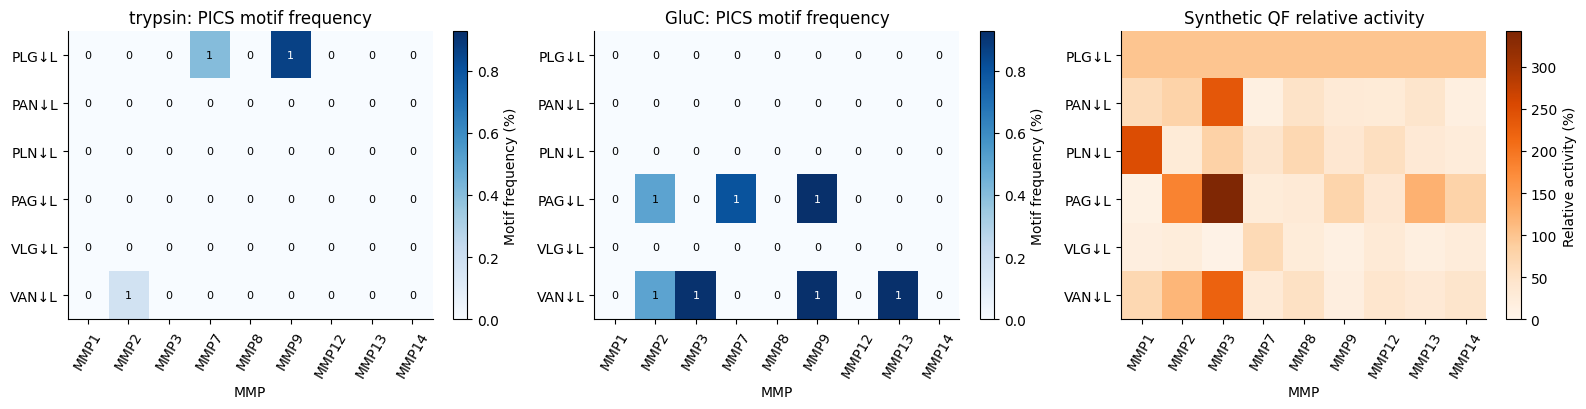

In [4]:
FIGURE_SIZE = (16, 4.2)
LIBRARIES = ("trypsin", "GluC")
ENZYMES = tuple(MMP_TO_MEROPS)

fig, axes = plt.subplots(1, 3, figsize=FIGURE_SIZE)
frequency_max = max(float(motif_frequencies["motif_frequency_percent"].max()), 1e-9)
for ax, library in zip(axes[:2], LIBRARIES):
    frame = motif_frequencies.loc[motif_frequencies["library"].eq(library)]
    frequency = frame.pivot(index="substrate", columns="enzyme", values="motif_frequency_percent").reindex(index=SUBSTRATE_LABELS, columns=ENZYMES)
    occurrences = frame.pivot(index="substrate", columns="enzyme", values="motif_occurrences").reindex(index=SUBSTRATE_LABELS, columns=ENZYMES)
    image = ax.imshow(frequency, aspect="auto", cmap="Blues", vmin=0, vmax=frequency_max)
    for i in range(6):
        for j in range(9):
            ax.text(j, i, str(occurrences.iat[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if frequency.iat[i, j] > frequency_max * 0.6 else "black")
    ax.set(title=f"{library}: PICS motif frequency", xticks=range(9), xticklabels=ENZYMES,
           yticks=range(6), yticklabels=SUBSTRATE_LABELS, xlabel="MMP")
    ax.tick_params(axis="x", rotation=60)
    fig.colorbar(image, ax=ax, label="Motif frequency (%)", fraction=0.045)
activity = qf["summary"].pivot(index="substrate", columns="enzyme", values="relative_activity_percent").reindex(index=SUBSTRATE_LABELS, columns=ENZYMES)
image = axes[2].imshow(activity, aspect="auto", cmap="Oranges", vmin=0)
axes[2].set(title="Synthetic QF relative activity", xticks=range(9), xticklabels=ENZYMES,
            yticks=range(6), yticklabels=SUBSTRATE_LABELS, xlabel="MMP")
axes[2].tick_params(axis="x", rotation=60)
fig.colorbar(image, ax=axes[2], label="Relative activity (%)", fraction=0.045)
fig.tight_layout()
plt.show()

### Remarks

A motif absent from these libraries is not demonstrated to be uncleavable. Designed QF substrates are a selected experimental panel, not a random sample of proteomic contexts. Counts are not weighted by QF activity, and one measured synthetic-substrate rate is not copied onto all natural windows with its motif. Preserve these evidence types and their source locators separately in the later integration.

### Notes

## Results / Summary

### LLM

The source-defined synthetic context is P3–P4′ with Dpa retained at P2′; P4 is unavailable. `context_associations` links motif-level source frequencies to the 54 reported enzyme–substrate activities without asserting complete chemical identity or producing additional kinetic measurements.

### Person

## Common numerical parameters

`common_parameters` contains numeric columns, including positional probabilities and their sum. PICS frequencies are occurrence counts divided by the observed total, separately by enzyme and library. QF relative activity follows the source normalization 100 × k/k_PLG; fluorescence slopes are refitted over the source-selected interval after averaging duplicate wells at each time. Source rounds and merged summaries remain identifiable. Missing Dpa probabilities are retained with explicit coverage. All transformations stay in memory; no CSV or database is written.

In [5]:
# Use the independent data library from this checkout.
import sys
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.integration.merge import (
    build_dataset, parse_dataset, add_merops_scores,
)
contract = build_dataset(
    ROOT / "data/proteolysis", sources=["mmp_pics", "mmp_pics_qf"],
)
contract = add_merops_scores(
    contract, ROOT / "data/proteolysis/window_neighbourhood_datasets/raw/merops",
    dataset_index=34,
)
common_parameters = contract.to_frame()
for mask in (common_parameters.cleavage_occurrence.notna(), common_parameters.relative_activity_percent.notna()):
    display(common_parameters.loc[mask & common_parameters.enzyme_name.eq("MMP1"), [
        "source_dataset", "enzyme_name", "window", "relative_activity_percent",
        "fluorescence_rate_au_s", "position_probability_sum", "probability_positions_scored",
    ]].head(6))


,source_dataset,enzyme_name,window,relative_activity_percent,fluorescence_rate_au_s,position_probability_sum,probability_positions_scored
0,trypsin,MMP1,V S M I | A S R K,NaN,NaN,0.291974,8
1,trypsin,MMP1,I V C - | A Y A H,NaN,NaN,0.557074,7
2,trypsin,MMP1,E P I P | C E Q L,NaN,NaN,0.612778,8
3,trypsin,MMP1,P V - D | C H T A,NaN,NaN,0.550051,7
4,trypsin,MMP1,T P D S | C I I S,NaN,NaN,0.761301,8
5,trypsin,MMP1,S N - - | C T T N,NaN,NaN,0.312864,6


,source_dataset,enzyme_name,window,relative_activity_percent,fluorescence_rate_au_s,position_probability_sum,probability_positions_scored
4026,QF,MMP1,- P L G | L Dpa A R,100.000000,1.126743,1.308933,6
4027,QF,MMP1,- P A N | L Dpa A R,59.679887,0.672235,1.030039,6
4028,QF,MMP1,- P L N | L Dpa A R,252.584779,2.850167,1.104113,6
4029,QF,MMP1,- P A G | L Dpa A R,10.773856,0.122015,1.234859,6
4030,QF,MMP1,- V L G | L Dpa A R,18.393568,0.204910,1.031824,6
4031,QF,MMP1,- V A N | L Dpa A R,71.211238,0.802388,0.752931,6
